In [1]:
import glob, time
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from IPython.display import display

FEAT = sorted({p.rsplit("/", 1)[0] for p in glob.glob("/kaggle/input/**/train_text.parquet", recursive=True)})[0]
train = pl.read_parquet(f"{FEAT}/train_text.parquet")
val   = pl.read_parquet(f"{FEAT}/val_text.parquet")
print(train.shape, val.shape)

CLASSES = sorted(train["product"].unique().to_list())
y_train = train["product"].to_numpy()
y_val   = val["product"].to_numpy()

(100000, 8) (50000, 8)


In [2]:
import joblib, glob
from pathlib import Path

CACHE = Path("/kaggle/working/cache"); CACHE.mkdir(parents=True, exist_ok=True)
REPORTS = Path("/kaggle/working/reports_l2"); REPORTS.mkdir(parents=True, exist_ok=True)

def cached(name, fn):
    """Recharge 'name' depuis working/cache ou n'importe quel input (Output précédent), sinon calcule."""
    candidates = [CACHE / name] + [Path(p) for p in glob.glob(f"/kaggle/input/**/{name}", recursive=True)]
    for path in candidates:
        if path.exists():
            obj = joblib.load(path)
            if path.parent != CACHE:
                joblib.dump(obj, CACHE / name)   # recopié pour que la version suivante l'ait aussi
            print(f"[cache] {name} rechargé")
            return obj
    t0 = time.time()
    obj = fn()
    joblib.dump(obj, CACHE / name)
    print(f"[cache] {name} calculé et sauvegardé ({time.time() - t0:.0f} s)")
    return obj

In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, accuracy_score

dummy = DummyClassifier(strategy="most_frequent").fit(np.zeros((len(y_train), 1)), y_train)
pred = dummy.predict(np.zeros((len(y_val), 1)))
print("Classe prédite :", pred[0])
print(f"Accuracy : {accuracy_score(y_val, pred):.3f}")
print(f"Macro-F1 : {f1_score(y_val, pred, average='macro'):.3f}")

Classe prédite : credit_reporting
Accuracy : 0.606
Macro-F1 : 0.075


In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

t0 = time.time()
vec = TfidfVectorizer(token_pattern=r"\S+", lowercase=False, ngram_range=(1, 2),
                      min_df=5, max_df=0.5, sublinear_tf=True, max_features=200_000)
X_train = vec.fit_transform(train["text_tfidf"].to_list())
X_val   = vec.transform(val["text_tfidf"].to_list())
print(f"TF-IDF : {X_train.shape[1]:,} colonnes ({time.time() - t0:.0f} s)")

def fit_logreg():
    t0 = time.time()
    m = LogisticRegression(max_iter=2000, C=4.0, n_jobs=-1).fit(X_train, y_train)
    return {"pred": m.predict(X_val), "fit_s": round(time.time() - t0)}

r = cached("pred_logreg.joblib", fit_logreg)        # ~2 min la 1re fois
pred = r["pred"]
print(f"Accuracy : {accuracy_score(y_val, pred):.3f}")
print(f"Macro-F1 : {f1_score(y_val, pred, average='macro'):.3f}")

TF-IDF : 200,000 colonnes (35 s)
[cache] pred_logreg.joblib rechargé
Accuracy : 0.848
Macro-F1 : 0.752


                      precision    recall  f1-score   support

    checking_savings      0.810     0.801     0.806      3843
         credit_card      0.736     0.728     0.732      3980
    credit_reporting      0.928     0.906     0.917     30275
     debt_collection      0.697     0.715     0.706      6010
      money_transfer      0.676     0.734     0.704      1325
            mortgage      0.837     0.909     0.871      1510
payday_personal_loan      0.493     0.578     0.532       631
        prepaid_card      0.670     0.760     0.712       462
        student_loan      0.838     0.889     0.863      1010
        vehicle_loan      0.628     0.737     0.678       954

            accuracy                          0.848     50000
           macro avg      0.731     0.776     0.752     50000
        weighted avg      0.851     0.848     0.849     50000



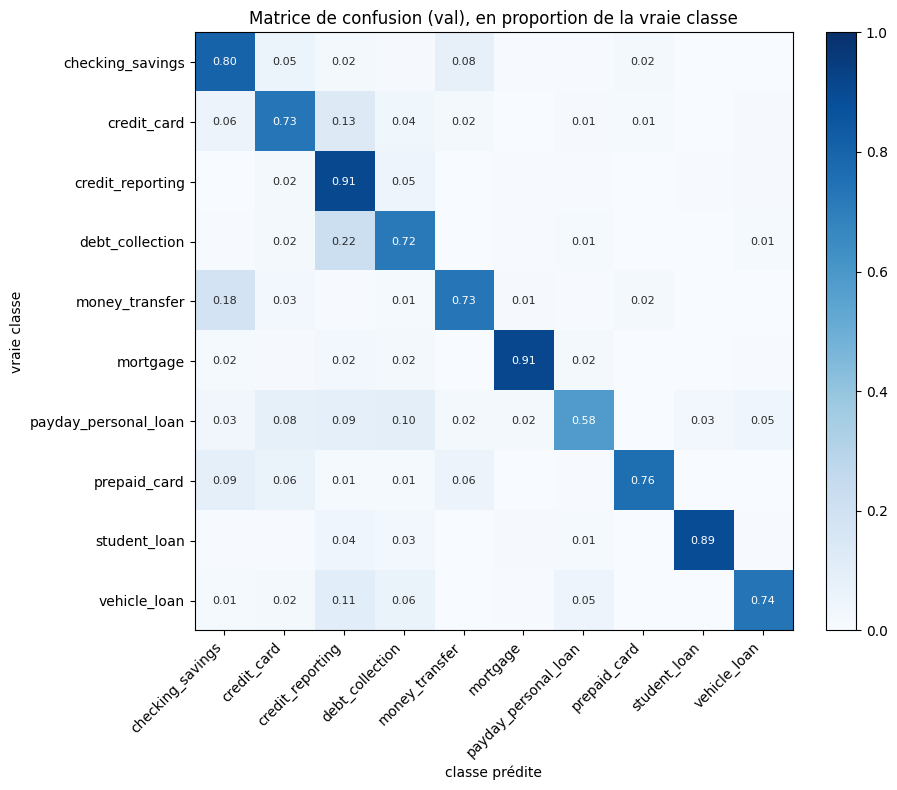

In [5]:
from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(y_val, pred, digits=3))

cm = confusion_matrix(y_val, pred, labels=CLASSES, normalize="true")
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=45, ha="right")
ax.set_yticks(range(len(CLASSES)), CLASSES)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        if cm[i, j] >= 0.01:
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                    color="white" if cm[i, j] > 0.5 else "#2b2b2b", fontsize=8)
ax.set_xlabel("classe prédite")
ax.set_ylabel("vraie classe")
ax.set_title("Matrice de confusion (val), en proportion de la vraie classe")
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

In [6]:
import os
os.makedirs("/kaggle/working/reports_l2", exist_ok=True)
results = [
    {"modèle": "Idiot (classe majoritaire)", "features": "-", "accuracy": 0.606, "macro_f1": 0.075},
    {"modèle": "Régression logistique", "features": "TF-IDF mots 1-2", "accuracy": 0.848, "macro_f1": 0.752},
]
pl.DataFrame(results).write_csv("/kaggle/working/reports_l2/results_val.csv")

In [7]:
from scipy.sparse import hstack

_char = {}
def char_feats():
    """TF-IDF caractères calculé seulement à la 1re demande (~3 min)."""
    if not _char:
        t0 = time.time()
        cvec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=5,
                               sublinear_tf=True, max_features=300_000, dtype=np.float32)
        _char["tr"] = cvec.fit_transform(train["text_full"].to_list())
        _char["va"] = cvec.transform(val["text_full"].to_list())
        _char["btr"] = hstack([X_train, _char["tr"]]).tocsr()
        _char["bva"] = hstack([X_val, _char["va"]]).tocsr()
        print(f"TF-IDF caractères : {_char['tr'].shape[1]:,} colonnes ({time.time() - t0:.0f} s)")
    return _char

In [8]:
preds = {"Régression logistique | mots": pred}

def evaluate(key, name, features, fit_predict):
    """fit_predict() entraîne et renvoie les prédictions val ; le résultat est mis en cache sous 'key'."""
    def run():
        t0 = time.time()
        return {"pred": fit_predict(), "fit_s": round(time.time() - t0)}
    r = cached(f"pred_{key}.joblib", run)
    p = r["pred"]
    res = {"modèle": name, "features": features,
           "accuracy": round(accuracy_score(y_val, p), 3),
           "macro_f1": round(f1_score(y_val, p, average="macro"), 3),
           "temps (s)": r["fit_s"]}
    results.append(res)
    preds[f"{name} | {features}"] = p
    print(res)
    return p

In [9]:
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import LinearSVC

RUN_SLOW = False   # True seulement pour recalculer caractères et LightGBM (~30 min)

KNOWN = {   # scores déjà mesurés, repris si RUN_SLOW = False et absents du cache
    "svm_chars": {"modèle": "SVM linéaire", "features": "caractères",
                  "accuracy": 0.845, "macro_f1": 0.747, "temps (s)": 210},
    "svm_combo": {"modèle": "SVM linéaire", "features": "mots + caractères",
                  "accuracy": 0.847, "macro_f1": 0.753, "temps (s)": 64},
    "lgbm":      {"modèle": "LightGBM", "features": "mots (20k chi2)",
                  "accuracy": 0.847, "macro_f1": 0.754, "temps (s)": 1159},
}

def in_cache(key):
    name = f"pred_{key}.joblib"
    return (CACHE / name).exists() or bool(glob.glob(f"/kaggle/input/**/{name}", recursive=True))

def evaluate_slow(key, name, features, fit_predict):
    """Comme evaluate, mais saute le calcul si RUN_SLOW = False et rien en cache."""
    if RUN_SLOW or in_cache(key):
        return evaluate(key, name, features, fit_predict)
    results.append(KNOWN[key])
    print(f"[skip] {key} : score repris de la version précédente -> {KNOWN[key]}")

evaluate("nb", "Naive Bayes", "mots",
         lambda: ComplementNB(alpha=0.3).fit(X_train, y_train).predict(X_val))
evaluate("svm_words", "SVM linéaire", "mots",
         lambda: LinearSVC(C=0.5).fit(X_train, y_train).predict(X_val))
evaluate_slow("svm_chars", "SVM linéaire", "caractères",
              lambda: LinearSVC(C=0.5).fit(char_feats()["tr"], y_train).predict(char_feats()["va"]))
evaluate_slow("svm_combo", "SVM linéaire", "mots + caractères",
              lambda: LinearSVC(C=0.5).fit(char_feats()["btr"], y_train).predict(char_feats()["bva"]));

[cache] pred_nb.joblib rechargé
{'modèle': 'Naive Bayes', 'features': 'mots', 'accuracy': 0.838, 'macro_f1': 0.714, 'temps (s)': 1}
[cache] pred_svm_words.joblib rechargé
{'modèle': 'SVM linéaire', 'features': 'mots', 'accuracy': 0.848, 'macro_f1': 0.754, 'temps (s)': 18}
[cache] pred_svm_chars.joblib rechargé
{'modèle': 'SVM linéaire', 'features': 'caractères', 'accuracy': 0.845, 'macro_f1': 0.747, 'temps (s)': 512}
[cache] pred_svm_combo.joblib rechargé
{'modèle': 'SVM linéaire', 'features': 'mots + caractères', 'accuracy': 0.847, 'macro_f1': 0.752, 'temps (s)': 98}


In [10]:
import lightgbm as lgb
from sklearn.feature_selection import SelectKBest, chi2

def fit_lgbm():
    sel = SelectKBest(chi2, k=20_000).fit(X_train, y_train)
    Xtr_s = sel.transform(X_train).astype(np.float32)
    Xva_s = sel.transform(X_val).astype(np.float32)
    m = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.1, num_leaves=63,
                           colsample_bytree=0.3, subsample=0.8, subsample_freq=1,
                           n_jobs=4, verbose=-1).fit(Xtr_s, y_train)
    return m.predict(Xva_s)

evaluate_slow("lgbm", "LightGBM", "mots (20k chi2)", fit_lgbm);

[cache] pred_lgbm.joblib rechargé
{'modèle': 'LightGBM', 'features': 'mots (20k chi2)', 'accuracy': 0.848, 'macro_f1': 0.755, 'temps (s)': 1553}


In [11]:
table = (pl.from_dicts(results, infer_schema_length=None)
         .sort("macro_f1", descending=True))
display(table)
table.write_csv("/kaggle/working/reports_l2/results_val.csv")

# F1 par classe pour chaque modèle
per_class = pl.DataFrame({"classe": CLASSES} | {
    name: np.round(f1_score(y_val, p, labels=CLASSES, average=None), 3) for name, p in preds.items()
})
with pl.Config(tbl_cols=20, tbl_width_chars=250, fmt_str_lengths=40):
    display(per_class)
per_class.write_csv("/kaggle/working/reports_l2/f1_per_class_val.csv")

modèle,features,accuracy,macro_f1,temps (s)
str,str,f64,f64,i64
"""LightGBM""","""mots (20k chi2)""",0.848,0.755,1553
"""SVM linéaire""","""mots""",0.848,0.754,18
"""Régression logistique""","""TF-IDF mots 1-2""",0.848,0.752,null
"""SVM linéaire""","""mots + caractères""",0.847,0.752,98
"""SVM linéaire""","""caractères""",0.845,0.747,512
"""Naive Bayes""","""mots""",0.838,0.714,1
"""Idiot (classe majoritaire)""","""-""",0.606,0.075,null


classe,Régression logistique | mots,Naive Bayes | mots,SVM linéaire | mots,SVM linéaire | caractères,SVM linéaire | mots + caractères,LightGBM | mots (20k chi2)
str,f64,f64,f64,f64,f64,f64
"""checking_savings""",0.806,0.793,0.805,0.801,0.804,0.815
"""credit_card""",0.732,0.703,0.733,0.727,0.729,0.734
"""credit_reporting""",0.917,0.915,0.917,0.916,0.916,0.917
"""debt_collection""",0.706,0.685,0.71,0.71,0.708,0.699
"""money_transfer""",0.704,0.672,0.701,0.687,0.696,0.707
"""mortgage""",0.871,0.799,0.867,0.866,0.87,0.882
"""payday_personal_loan""",0.532,0.379,0.544,0.523,0.549,0.534
"""prepaid_card""",0.712,0.732,0.719,0.706,0.715,0.715
"""student_loan""",0.863,0.803,0.859,0.86,0.858,0.87


In [12]:
!pip install -q optuna
import optuna, warnings
from sklearn.svm import LinearSVC
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Récits uniques disponibles par classe avant échantillonnage (train <= 2023, README §4)
POOL = {"credit_reporting": 569_176, "debt_collection": 217_966, "credit_card": 121_859,
        "mortgage": 112_942, "checking_savings": 101_743, "student_loan": 39_948,
        "money_transfer": 38_190, "vehicle_loan": 33_968, "payday_personal_loan": 23_654,
        "prepaid_card": 12_417}
N_TRAIN = dict(train.group_by("product").len().iter_rows())

def class_weights(alpha_target: float) -> dict:
    """Poids qui font 'comme si' le train avait été tiré avec alpha_target au lieu de 0,5."""
    raw = {c: POOL[c] ** (alpha_target - 0.5) for c in CLASSES}
    mean = sum(raw[c] * N_TRAIN[c] for c in CLASSES) / sum(N_TRAIN.values())
    return {c: raw[c] / mean for c in CLASSES}

def objective(trial):
    C = trial.suggest_float("C", 0.01, 10, log=True)
    a = trial.suggest_float("alpha", 0.0, 1.0)
    m = LinearSVC(C=C, class_weight=class_weights(a)).fit(X_train, y_train)
    return f1_score(y_val, m.predict(X_val), average="macro")

def run_optuna():
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
    study.enqueue_trial({"C": 0.5, "alpha": 0.5})
    study.optimize(objective, n_trials=30, show_progress_bar=True)
    trials = (pl.DataFrame([{"C": round(t.params["C"], 4), "alpha": round(t.params["alpha"], 2),
                             "macro_f1": round(t.value, 4)} for t in study.trials])
              .sort("macro_f1", descending=True))
    return {"best_params": study.best_params, "best_value": study.best_value, "trials": trials}

opt = cached("optuna_svm.joblib", run_optuna)      # ~10 min la 1re fois, ~1 s ensuite
best_params, trials = opt["best_params"], opt["trials"]
display(trials.head(10))
print("Meilleur :", best_params, f"macro-F1 = {opt['best_value']:.4f}")

[cache] optuna_svm.joblib rechargé


C,alpha,macro_f1
f64,f64,f64
0.1613,0.75,0.7626
0.2846,0.73,0.7624
0.2121,0.7,0.7621
0.4221,0.84,0.7619
0.1126,0.81,0.7603
0.2491,0.62,0.7603
0.084,0.74,0.7584
0.0783,0.8,0.758
0.1329,0.95,0.7579


Meilleur : {'C': 0.16126585182521488, 'alpha': 0.7472349168029719} macro-F1 = 0.7626


alpha,macro_f1,accuracy,précision petites classes,rappel petites classes,rappel credit_reporting
f64,f64,f64,f64,f64,f64
0.0,0.7366,0.8379,0.512,0.754,0.883
0.25,0.7506,0.8463,0.57,0.726,0.897
0.5,0.7574,0.8514,0.624,0.686,0.909
0.75,0.7622,0.8557,0.686,0.641,0.919
1.0,0.7579,0.857,0.742,0.584,0.927


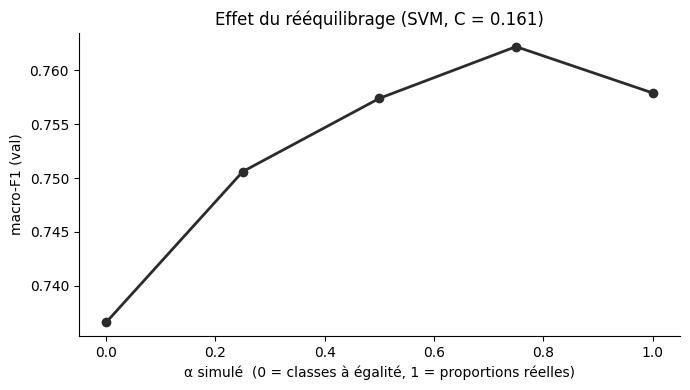

In [13]:
from sklearn.metrics import precision_score, recall_score

best_C = best_params["C"]
SMALL = ["payday_personal_loan", "prepaid_card", "vehicle_loan"]
rows = []
for a in [0.0, 0.25, 0.5, 0.75, 1.0]:
    m = LinearSVC(C=best_C, class_weight=class_weights(a)).fit(X_train, y_train)
    p = m.predict(X_val)
    rows.append({
        "alpha": a,
        "macro_f1": round(f1_score(y_val, p, average="macro"), 4),
        "accuracy": round(accuracy_score(y_val, p), 4),
        "précision petites classes": round(precision_score(y_val, p, labels=SMALL, average="macro"), 3),
        "rappel petites classes": round(recall_score(y_val, p, labels=SMALL, average="macro"), 3),
        "rappel credit_reporting": round(recall_score(y_val, p, labels=["credit_reporting"], average="macro"), 3),
    })
alpha_effect = pl.DataFrame(rows)
display(alpha_effect)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(alpha_effect["alpha"], alpha_effect["macro_f1"], color="#2b2b2b", lw=2, marker="o")
ax.set_xlabel("α simulé  (0 = classes à égalité, 1 = proportions réelles)")
ax.set_ylabel("macro-F1 (val)")
ax.set_title(f"Effet du rééquilibrage (SVM, C = {best_C:.3g})")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.savefig("/kaggle/working/reports_l2/alpha_effect.png", dpi=150)
plt.show()

In [14]:
best_svm = LinearSVC(C=best_C, class_weight=class_weights(best_params["alpha"])).fit(X_train, y_train)
base_svm = LinearSVC(C=0.5).fit(X_train, y_train)
p_best, p_base = best_svm.predict(X_val), base_svm.predict(X_val)

idx_of = {c: i for i, c in enumerate(CLASSES)}
yv = np.array([idx_of[c] for c in y_val])
pb = np.array([idx_of[c] for c in p_best])
p0 = np.array([idx_of[c] for c in p_base])
K = len(CLASSES)

def macro_f1_fast(y, p):
    cm = np.bincount(y * K + p, minlength=K * K).reshape(K, K)
    tp = np.diag(cm)
    with np.errstate(divide="ignore", invalid="ignore"):
        prec = np.nan_to_num(tp / cm.sum(0))
        rec = np.nan_to_num(tp / cm.sum(1))
        f1 = np.nan_to_num(2 * prec * rec / (prec + rec))
    return f1.mean()

rng = np.random.default_rng(42)
n, B = len(yv), 1_000
sb, s0 = np.empty(B), np.empty(B)
for b in range(B):
    i = rng.integers(0, n, n)
    sb[b], s0[b] = macro_f1_fast(yv[i], pb[i]), macro_f1_fast(yv[i], p0[i])
diff = sb - s0

ci = lambda x: f"[{np.percentile(x, 2.5):.4f} ; {np.percentile(x, 97.5):.4f}]"
print(f"SVM de départ : {macro_f1_fast(yv, p0):.4f}  IC 95 % {ci(s0)}")
print(f"SVM réglé     : {macro_f1_fast(yv, pb):.4f}  IC 95 % {ci(sb)}")
print(f"Gain          : {np.mean(diff):+.4f}  IC 95 % {ci(diff)}")
print(f"Part des tirages où le SVM réglé ne gagne pas : {(diff <= 0).mean():.3f}")

results.append({"modèle": "SVM linéaire réglé", "features": "mots",
                "accuracy": round(accuracy_score(y_val, p_best), 3),
                "macro_f1": round(f1_score(y_val, p_best, average="macro"), 3), "temps (s)": None})
preds["SVM linéaire réglé | mots"] = p_best

SVM de départ : 0.7542  IC 95 % [0.7473 ; 0.7605]
SVM réglé     : 0.7626  IC 95 % [0.7554 ; 0.7690]
Gain          : +0.0085  IC 95 % [0.0050 ; 0.0124]
Part des tirages où le SVM réglé ne gagne pas : 0.000


In [15]:
names = vec.get_feature_names_out()
rows = []
for i, c in enumerate(best_svm.classes_):
    top = np.argsort(best_svm.coef_[i])[-12:][::-1]
    rows.append({"classe": c, "mots les plus décisifs": ", ".join(names[top])})
with pl.Config(fmt_str_lengths=200, tbl_width_chars=250):
    display(pl.DataFrame(rows))

print(classification_report(y_val, p_best, digits=3))

classe,mots les plus décisifs
str,str
"""checking_savings""","""bank, branch, overdraft, chime, deposit, debit card, checking, cd, debit, saving, banking, check"""
"""credit_card""","""card, credit card, capital, barclay, citi, synchrony, reward, charge, comenity, discover, chase, balance transfer"""
"""credit_reporting""","""experian, equifax, transunion, report, inquiry, score, incorrect, trans union, remove, trans, reporting, usc_1681"""
"""debt_collection""","""debt, collection, owe, recovery, collect, inc, midland, call, medical, erc, bill, company"""
"""money_transfer""","""coinbase, paypal, venmo, transfer, wire, zelle, money, moneygram, western union, send [MONEY], send money, western"""
"""mortgage""","""mortgage, escrow, modification, home, foreclosure, appraisal, property, closing, ocwen, house, loancare, ditech"""
"""payday_personal_loan""","""loan, personal loan, title loan, borrow, payday, line credit, main financial, installment, affirm, installment loan, [MONEY] loan, loan [MONEY]"""
"""prepaid_card""","""card, prepaid, netspend, unemployment, prepay, edd, gift, direct express, reliacard, bluebird, rushcard, gift card"""
"""student_loan""","""navient, nelnet, mohela, student, fedloan, school, student loan, loan, repayment, aes, aidvantage, edfinancial"""


                      precision    recall  f1-score   support

    checking_savings      0.812     0.812     0.812      3843
         credit_card      0.752     0.737     0.745      3980
    credit_reporting      0.924     0.919     0.922     30275
     debt_collection      0.715     0.715     0.715      6010
      money_transfer      0.698     0.715     0.706      1325
            mortgage      0.822     0.931     0.873      1510
payday_personal_loan      0.614     0.485     0.542       631
        prepaid_card      0.767     0.706     0.735       462
        student_loan      0.838     0.900     0.868      1010
        vehicle_loan      0.680     0.739     0.708       954

            accuracy                          0.856     50000
           macro avg      0.762     0.766     0.763     50000
        weighted avg      0.856     0.856     0.855     50000



In [16]:
trials.write_csv("/kaggle/working/reports_l2/optuna_svm_trials.csv")
alpha_effect.write_csv("/kaggle/working/reports_l2/alpha_effect.csv")
pl.DataFrame(rows).write_csv("/kaggle/working/reports_l2/top_features_svm.csv")
pl.from_dicts(results, infer_schema_length=None).sort("macro_f1", descending=True) \
  .write_csv("/kaggle/working/reports_l2/results_val.csv")
!ls -la /kaggle/working/reports_l2

total 80
drwxr-xr-x 2 root root  4096 Nov 13 12:51 .
drwxr-xr-x 4 root root  4096 Nov 13 12:48 ..
-rw-r--r-- 1 root root   278 Nov 13 12:51 alpha_effect.csv
-rw-r--r-- 1 root root 51021 Nov 13 12:50 alpha_effect.png
-rw-r--r-- 1 root root   667 Nov 13 12:49 f1_per_class_val.csv
-rw-r--r-- 1 root root   571 Nov 13 12:51 optuna_svm_trials.csv
-rw-r--r-- 1 root root   376 Nov 13 12:51 results_val.csv
-rw-r--r-- 1 root root  1311 Nov 13 12:51 top_features_svm.csv


In [17]:
import json
(REPORTS / "best_svm_params.json").write_text(json.dumps(best_params, indent=2))

61

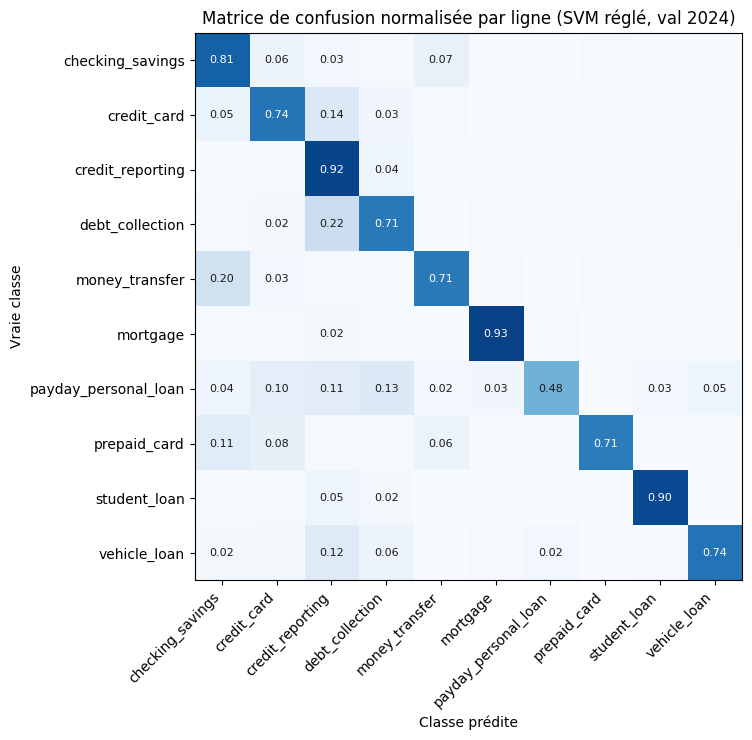

vraie,prédite,len
str,str,u32
"""debt_collection""","""credit_reporting""",1337
"""credit_reporting""","""debt_collection""",1335
"""credit_card""","""credit_reporting""",554
"""credit_reporting""","""credit_card""",449
"""checking_savings""","""money_transfer""",272
"""money_transfer""","""checking_savings""",261
"""checking_savings""","""credit_card""",217
"""credit_card""","""checking_savings""",208
"""credit_reporting""","""vehicle_loan""",202


In [18]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_val, p_best, labels=CLASSES, normalize="true")
fig, ax = plt.subplots(figsize=(9, 7.5))
ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=45, ha="right")
ax.set_yticks(range(len(CLASSES)), CLASSES)
ax.set_xlabel("Classe prédite"); ax.set_ylabel("Vraie classe")
ax.set_title("Matrice de confusion normalisée par ligne (SVM réglé, val 2024)")
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        if cm[i, j] >= 0.02:
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if cm[i, j] > 0.5 else "#1a1a1a")
plt.tight_layout(); plt.savefig(REPORTS / "confusion_svm.png", dpi=150); plt.show()

pairs = (pl.DataFrame({"vraie": y_val, "prédite": p_best})
         .filter(pl.col("vraie") != pl.col("prédite"))
         .group_by("vraie", "prédite").len().sort("len", descending=True))
display(pairs.head(10))

In [19]:
scores = best_svm.decision_function(X_val)
cls = list(best_svm.classes_)
yv_arr, pb_arr = np.array(y_val), np.array(p_best)
true_idx = np.array([cls.index(c) for c in yv_arr])
gap = scores.max(1) - scores[np.arange(len(yv_arr)), true_idx]   # 0 si correct, grand = erreur sûre

err = (val.select("complaint_id", "product", "text_light")
       .with_columns(pl.Series("prédite", pb_arr), pl.Series("écart", gap.round(3)))
       .filter(pl.col("product") != pl.col("prédite")))

top_pairs = pairs.head(4).rows()          # 4 confusions les plus fréquentes
sample = pl.concat([
    err.filter((pl.col("product") == v) & (pl.col("prédite") == p)).sample(min(20, n), seed=42)
    for v, p, n in top_pairs
] + [err.filter(pl.col("product") == "payday_personal_loan").sample(20, seed=42)])

sample = (sample.unique("complaint_id")
          .with_columns(pl.col("text_light").str.slice(0, 1500),
                        pl.lit("").alias("cause"))          # à remplir à la main
          .sort("product", "prédite"))
sample.write_csv(REPORTS / "errors_sample.csv")
print(f"{sample.height} erreurs exportées")

for r in sample.head(3).iter_rows(named=True):
    print(f"\n[{r['product']} -> prédit {r['prédite']}, écart {r['écart']}]\n{r['text_light'][:600]}")

100 erreurs exportées

[credit_card -> prédit credit_reporting, écart 0.473]
Dear FORTIVA/ The Bank of [PII] and its Representatives, I have been searching high and low for some vital information. I have not been able to get this specific information from any customer service representative or through any online search through the Securities and Exchange Commission. I need the most correct, up to date information for the following as soon as possible. Please give me the correct contact information including the contact Name and Title of the person or Senior Officer, their correct phone number, mailing address, e-mail address, and fax number for this or these representa

[credit_card -> prédit credit_reporting, écart 1.39]
someone opened an account in [PII] and never gave permission and has been disputing it for years. just found out about [PII] and how to remove unauthorized accounts on my file etc..

[credit_card -> prédit credit_reporting, écart 3.292]
I noticed on my transunion repo

In [20]:
from sklearn.base import clone

def run_ablation(col, vectorizer):
    v = clone(vectorizer)
    Xtr, Xva = v.fit_transform(train[col]), v.transform(val[col])
    m = LinearSVC(C=best_params["C"], class_weight=class_weights(best_params["alpha"])).fit(Xtr, y_train)
    p = m.predict(Xva)
    return {"macro_f1": round(f1_score(y_val, p, average="macro"), 4),
            "accuracy": round(accuracy_score(y_val, p), 4), "n_features": Xtr.shape[1]}

configs = {
    "text_tfidf, mots 1-2 (référence)": ("text_tfidf", vec),
    "text_tfidf, mots 1 seulement":     ("text_tfidf", clone(vec).set_params(ngram_range=(1, 1))),
    "text_full (sans lemmes, avec mots vides), mots 1-2": ("text_full", vec),
}
abl = pl.DataFrame([{"config": name, **cached(f"abl_{i}.joblib", lambda c=c, v=v: run_ablation(c, v))}
                    for i, (name, (c, v)) in enumerate(configs.items())])
display(abl)
abl.write_csv(REPORTS / "ablation_preprocessing.csv")

[cache] abl_0.joblib rechargé
[cache] abl_1.joblib rechargé
[cache] abl_2.joblib rechargé


config,macro_f1,accuracy,n_features
str,f64,f64,i64
"""text_tfidf, mots 1-2 (référenc…",0.7626,0.8557,200000
"""text_tfidf, mots 1 seulement""",0.7521,0.8472,13570
"""text_full (sans lemmes, avec m…",0.754,0.8534,200000


In [21]:
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS as STOPWORDS_EN

# 1. Colonne company depuis les splits (on ne lit que 2 colonnes)
split_files = [p for p in glob.glob("/kaggle/input/**/*.parquet", recursive=True)
               if "_text" not in p and Path(p).stem in {"train", "val"}]
print(split_files)
companies = pl.concat([pl.read_parquet(p, columns=["complaint_id", "company"]) for p in split_files]).unique("complaint_id")
train_c = train.join(companies, on="complaint_id", how="left")
print("company manquante dans train :", train_c["company"].null_count())

# 2. Tokens distinctifs des entreprises présentes au moins 30 fois dans le train
GENERIC = set("""bank banks banking financial finance services service servicing inc llc corp corporation company co
n.a. na national association group holdings holding credit card cards mortgage loan loans lending lender the of and
america american usa us u.s. one first federal trust savings capital solutions systems management partners
recovery collection collections agency associates consumer home auto student education funding fund
international global united state states north south east west new city community union intermediate llp ltd lp
plc fsb dba d/b/a payment payments money network technologies operations""".split())

top_cos = (train_c.group_by("company").len().filter(pl.col("len") >= 30)["company"].to_list())
tokens = set()
for name in top_cos:
    for t in re.findall(r"[a-z][a-z&'.-]+", name.lower()):
        t = t.strip(".-'")
        if len(t) >= 3 and t not in GENERIC and t not in STOPWORDS_EN:
            tokens.add(t)
print(f"{len(top_cos)} entreprises -> {len(tokens)} tokens masqués")
print(sorted(tokens)[:150])

['/kaggle/input/datasets/abdelbakimougari/complaintlens-splits/splits/train.parquet', '/kaggle/input/datasets/abdelbakimougari/complaintlens-splits/splits/val.parquet']
company manquante dans train : 0
283 entreprises -> 329 tokens masqués
['aargon', 'ability', 'acceptance', 'accounts', 'ace', 'acima', 'acs', 'adjusters', 'adp', 'advance', 'aes', 'affirm', 'afni', 'air', 'albert', 'alliant', 'ally', 'americollect', 'amerihome', 'amerisave', 'amsher', 'analytics', 'army', 'arvest', 'asset', 'astra', 'atlanticus', 'automobile', 'avant', 'avenue', 'axos', 'bam', 'banco', 'bancorp', 'bancorporation', 'barclays', 'bayview', 'bb&t', 'bbva', 'benz', 'big', 'blackhawk', 'bliksum', 'block', 'bluechip', 'bmo', 'bmw', 'bpo', 'branch', 'brands', 'bread', 'bridgecrest', 'broker', 'bsi', 'bureau', 'business', 'byrider', 'caine', 'caliber', 'callers', 'capio', 'cardinal', 'carmax', 'carrington', 'carvana', 'cash', 'cavalry', 'cbc', 'cbe', 'ccf', 'ccs', 'center', 'centers', 'charles', 'chase', 'chime'

In [22]:
# 3. Masquage dans text_tfidf (train et val)
pattern = r"\b(?:" + "|".join(sorted((re.escape(t) for t in tokens), key=len, reverse=True)) + r")\b"
train_m = train.with_columns(pl.col("text_tfidf").str.replace_all(pattern, "[COMPANY]").alias("text_masked"))
val_m   = val.with_columns(pl.col("text_tfidf").str.replace_all(pattern, "[COMPANY]").alias("text_masked"))
print(val_m["text_masked"][0][:400])

# 4. Réentraînement avec les mêmes réglages
def run_masked():
    v = clone(vec)
    Xtr, Xva = v.fit_transform(train_m["text_masked"]), v.transform(val_m["text_masked"])
    m = LinearSVC(C=best_params["C"], class_weight=class_weights(best_params["alpha"])).fit(Xtr, y_train)
    p = m.predict(Xva)
    names = v.get_feature_names_out()
    top = {c: ", ".join(names[np.argsort(m.coef_[i])[-12:][::-1]]) for i, c in enumerate(m.classes_)}
    return {"pred": p, "top": top}

res_m = cached("abl_company_masked.joblib", run_masked)
p_mask = res_m["pred"]

comp = pl.DataFrame({
    "classe": CLASSES,
    "f1_référence": f1_score(y_val, p_best, labels=CLASSES, average=None).round(3),
    "f1_masqué":    f1_score(y_val, p_mask, labels=CLASSES, average=None).round(3),
}).with_columns((pl.col("f1_masqué") - pl.col("f1_référence")).round(3).alias("écart")).sort("écart")
display(comp)
print(f"macro-F1 référence : {f1_score(y_val, p_best, average='macro'):.4f}")
print(f"macro-F1 masqué    : {f1_score(y_val, p_mask, average='macro'):.4f}")

with pl.Config(fmt_str_lengths=200, tbl_width_chars=250):
    display(pl.DataFrame({"classe": list(res_m["top"]), "top mots (masqué)": list(res_m["top"].values())}))

comp.write_csv(REPORTS / "ablation_company_mask.csv")

victim identity theft [COMPANY] [NUM] unidentified fraudulent hard inquiry credit report remove fradulent hard inquire [COMPANY] [NUM] fradulent [COMPANY] hard inquiry [PII] remove [COMPANY] [NUM] fraudulent hard inquiry
[cache] abl_company_masked.joblib rechargé


classe,f1_référence,f1_masqué,écart
str,f64,f64,f64
"""student_loan""",0.868,0.82,-0.048
"""money_transfer""",0.706,0.672,-0.034
"""payday_personal_loan""",0.542,0.51,-0.032
"""debt_collection""",0.715,0.695,-0.02
"""vehicle_loan""",0.708,0.688,-0.02
"""checking_savings""",0.812,0.793,-0.019
"""credit_card""",0.745,0.73,-0.015
"""mortgage""",0.873,0.86,-0.013
"""prepaid_card""",0.735,0.729,-0.006


macro-F1 référence : 0.7626
macro-F1 masqué    : 0.7416


classe,top mots (masqué)
str,str
"""checking_savings""","""bank, overdraft, deposit, debit card, checking, cd, banking, saving, check account, check, debit, saving account"""
"""credit_card""","""card, credit card, capital, citi, barclay, reward, charge, comenity, balance transfer, american [COMPANY], capitol, statement"""
"""credit_reporting""","""report, inquiry, score, incorrect, remove, investigation, usc_1681, trans union, freeze, reporting, trans, inaccurate"""
"""debt_collection""","""collection, collect, owe, recovery, collector, inc, midland, call, company, validation, llc, credit system"""
"""money_transfer""","""venmo, transfer, [COMPANY] union, wire, money, zelle, bitcoin, send [MONEY], usd, send money, crypto, transaction"""
"""mortgage""","""mortgage, escrow, modification, foreclosure, home, appraisal, property, closing, house, pmi, refinance, servicing"""
"""payday_personal_loan""","""loan, personal loan, title loan, payday, borrow, line credit, main financial, installment, [MONEY] loan, installment loan, loan [MONEY], lending [COMPANY]"""
"""prepaid_card""","""card, prepaid, prepay, unemployment, edd, direct [COMPANY], gift, reliacard, bluebird, rushcard, gift card, prepaid card"""
"""student_loan""","""student, loan, repayment, student loan, school, forbearance, fedloan, private loan, pslf, education, private, aidvantage"""


In [23]:
import copy
MODELS = Path("/kaggle/working/models"); MODELS.mkdir(exist_ok=True)
vec_light = copy.copy(vec)
vec_light.stop_words_ = None     # liste des termes écartés par min_df/max_df : inutile et très lourde
joblib.dump({"vectorizer": vec_light, "model": best_svm, "params": best_params, "classes": CLASSES},
            MODELS / "svm_tfidf_v1.joblib", compress=3)
!ls -la /kaggle/working/models

total 16392
drwxr-xr-x 2 root root     4096 Nov 13 12:51 .
drwxr-xr-x 5 root root     4096 Nov 13 12:51 ..
-rw-r--r-- 1 root root 16776424 Nov 13 12:51 svm_tfidf_v1.joblib
